GENERATIVE AI — PRACTICAL NO. 03

Title: Autoencoder and Variational Autoencoder for Image Reconstruction and Generation

Submitted By:

Name: Tanishka Vishnu Tapkir

Branch: AIML

PRN: 202401110071


Aim and Objectives
1.1 Aim

To implement an Autoencoder (AE) and a Variational Autoencoder (VAE) using deep learning techniques for image reconstruction and generation, and compare their performance based on reconstruction quality and image generation capabilities.

1.2 Objectives

To understand the working principles of Autoencoders and Variational Autoencoders.
To implement a Fully Connected Autoencoder for image reconstruction.
To implement a Fully Connected Variational Autoencoder for image reconstruction and generation.
To train both models using the MNIST handwritten digit dataset.
To visualize and compare original images with their reconstructed images.
To generate new handwritten digit images using the trained VAE.
To evaluate and compare both models using reconstruction loss and visual results.

1.3 Expected Outcome

After completing this practical, we will be able to understand how Autoencoders learn compressed representations of images, how Variational Autoencoders learn a probabilistic latent space, and how these models can be used for image reconstruction and generation.

# Software Requirements and Theoretical Background

## 2.1 Software and Hardware Requirements

| Sr. No. | Requirement             | Description                          |
| ------- | ----------------------- | ------------------------------------ |
| 1       | Platform                | Google Colab                         |
| 2       | Programming Language    | Python                               |
| 3       | Deep Learning Framework | PyTorch                              |
| 4       | Dataset                 | MNIST handwritten digit dataset      |
| 5       | Visualization Library   | Matplotlib                           |
| 6       | Numerical Library       | NumPy                                |
| 7       | Dataset Library         | Torchvision                          |
| 8       | Hardware                | CPU or GPU supported by Google Colab |

##2.2 Introduction to Autoencoder (AE)

An Autoencoder (AE) is an unsupervised neural network that learns a compressed representation of input data and reconstructs the original data from that representation.

It consists of three main components:

1. Encoder: Converts the input image into a lower-dimensional representation.

2. Latent Representation: Stores the compressed features extracted from the input image.

3. Decoder: Uses the compressed representation to reconstruct the original image.

       Input Image
        784 Values
             |
             v
       +-----------+
       |  Encoder  |
       +-----------+
             |
             v
       +-----------+
       |   Latent  |
       |   Space   |
       +-----------+
             |
             v
       +-----------+
       |  Decoder  |
       +-----------+
             |
             v
   Reconstructed Image
        784 Values2.5
        
        
##Dataset Description:

For this practical, we will use the MNIST handwritten digit dataset.

It contains 60,000 training images and 10,000 testing images.
Each image is a grayscale image of size 28 × 28 pixels.
The dataset contains handwritten digits from 0 to 9.
Pixel values will be converted to tensors and normalized to the range 0–1.

The dataset will be used to train both models, evaluate their reconstruction performance, and generate new digit images using the VAE.

## 1. Import the required Libraries

In [1]:
# Step 4: Import Required Libraries

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np

# Select the available computing device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Computing device:", device)

All libraries imported successfully!
PyTorch version: 2.11.0+cpu
Computing device: cpu


## 2.Load MNIST Dataset

In [2]:
# Load MNIST Dataset

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("MNIST Dataset Loaded Successfully!")
print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))
print("Image Shape:", train_dataset[0][0].shape)
print("Number of Batches:", len(train_loader))

100%|██████████| 9.91M/9.91M [00:00<00:00, 38.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.07MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.4MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.87MB/s]


MNIST Dataset Loaded Successfully!
Training Images: 60000
Testing Images: 10000
Image Shape: torch.Size([1, 28, 28])
Number of Batches: 469


## 3. Display MNIST Images


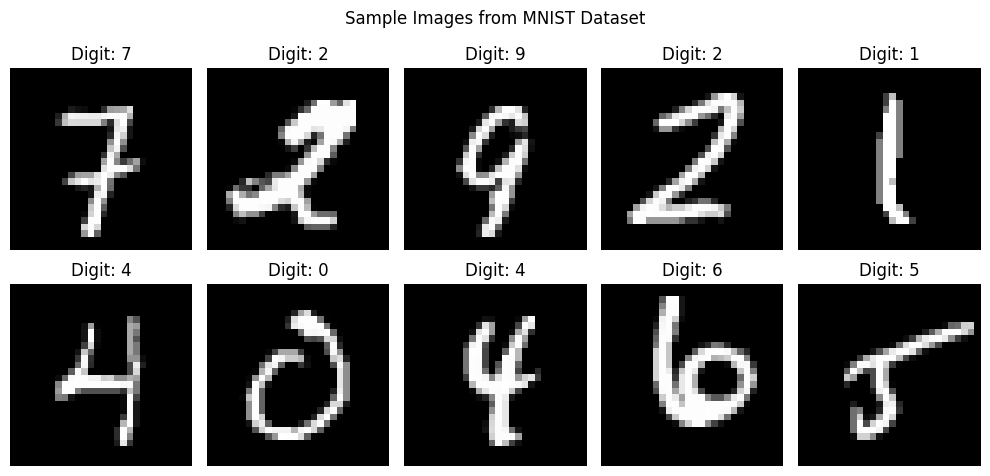

In [3]:
# Display Sample MNIST Images

images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(f"Digit: {labels[i].item()}")
    plt.axis("off")

plt.suptitle("Sample Images from MNIST Dataset")
plt.tight_layout()
plt.show()

## 4. Bild the Autoencoder


In [4]:
# Define Autoencoder Model

class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded.view(-1, 1, 28, 28)


# Initialize Autoencoder
ae_model = Autoencoder().to(device)

print(ae_model)

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


## 5. Train the AutoEncoder


In [5]:
# Train the Autoencoder

criterion = nn.MSELoss()
ae_optimizer = optim.Adam(ae_model.parameters(), lr=0.001)

ae_epochs = 5
ae_losses = []

for epoch in range(ae_epochs):
    ae_model.train()
    running_loss = 0.0

    for images, _ in train_loader:
        images = images.to(device)

        ae_optimizer.zero_grad()

        outputs = ae_model(images)
        loss = criterion(outputs, images)

        loss.backward()
        ae_optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    ae_losses.append(epoch_loss)

    print(f"Epoch [{epoch + 1}/{ae_epochs}], Loss: {epoch_loss:.4f}")

print("Autoencoder training completed!")

Epoch [1/5], Loss: 0.0426
Epoch [2/5], Loss: 0.0169
Epoch [3/5], Loss: 0.0125
Epoch [4/5], Loss: 0.0103
Epoch [5/5], Loss: 0.0090
Autoencoder training completed!


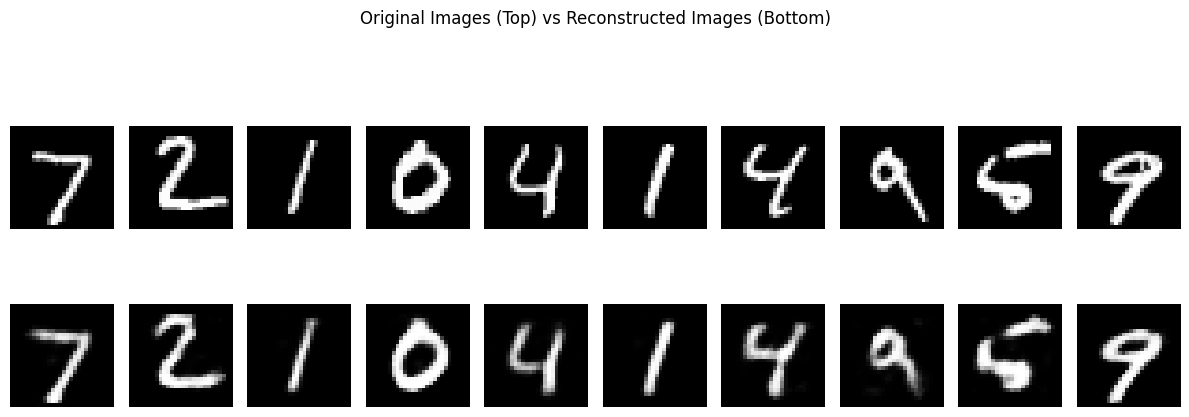

In [6]:
# Display Original and Reconstructed Images

ae_model.eval()

images, _ = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    reconstructed = ae_model(images)

images = images.cpu()
reconstructed = reconstructed.cpu()

plt.figure(figsize=(12, 5))

for i in range(10):
    # Original images
    plt.subplot(2, 10, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.axis("off")

    # Reconstructed images
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("Original Images (Top) vs Reconstructed Images (Bottom)")
plt.tight_layout()
plt.show()

## 6. Building Variational AutoEncoder


In [8]:
# Define Variational Autoencoder

class VAE(nn.Module):
    def __init__(self, latent_dim=20):
        super(VAE, self).__init__()

        # Encoder
        self.fc1 = nn.Linear(784, 256)
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        # Decoder
        self.fc2 = nn.Linear(latent_dim, 256)
        self.fc3 = nn.Linear(256, 784)

    def encode(self, x):
        x = x.view(-1, 784)
        h = torch.relu(self.fc1(x))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = torch.relu(self.fc2(z))
        return torch.sigmoid(self.fc3(h))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z)
        return reconstructed.view(-1, 1, 28, 28), mu, logvar


# Initialize VAE
vae_model = VAE().to(device)

print(vae_model)

VAE(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc_mu): Linear(in_features=256, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=20, bias=True)
  (fc2): Linear(in_features=20, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=784, bias=True)
)


In [9]:
# Train the Variational Autoencoder

def vae_loss_function(reconstructed, original, mu, logvar):
    reconstruction_loss = nn.functional.binary_cross_entropy(
        reconstructed.view(-1, 784),
        original.view(-1, 784),
        reduction="sum"
    )

    kl_divergence = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return (reconstruction_loss + kl_divergence) / original.size(0)


vae_optimizer = optim.Adam(vae_model.parameters(), lr=0.001)

vae_epochs = 5
vae_losses = []

for epoch in range(vae_epochs):
    vae_model.train()
    running_loss = 0.0

    for images, _ in train_loader:
        images = images.to(device)

        vae_optimizer.zero_grad()

        reconstructed, mu, logvar = vae_model(images)
        loss = vae_loss_function(reconstructed, images, mu, logvar)

        loss.backward()
        vae_optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    vae_losses.append(epoch_loss)

    print(f"Epoch [{epoch + 1}/{vae_epochs}], Loss: {epoch_loss:.4f}")

print("VAE training completed!")

Epoch [1/5], Loss: 175.0253
Epoch [2/5], Loss: 127.9705
Epoch [3/5], Loss: 118.9424
Epoch [4/5], Loss: 114.7915
Epoch [5/5], Loss: 112.6083
VAE training completed!


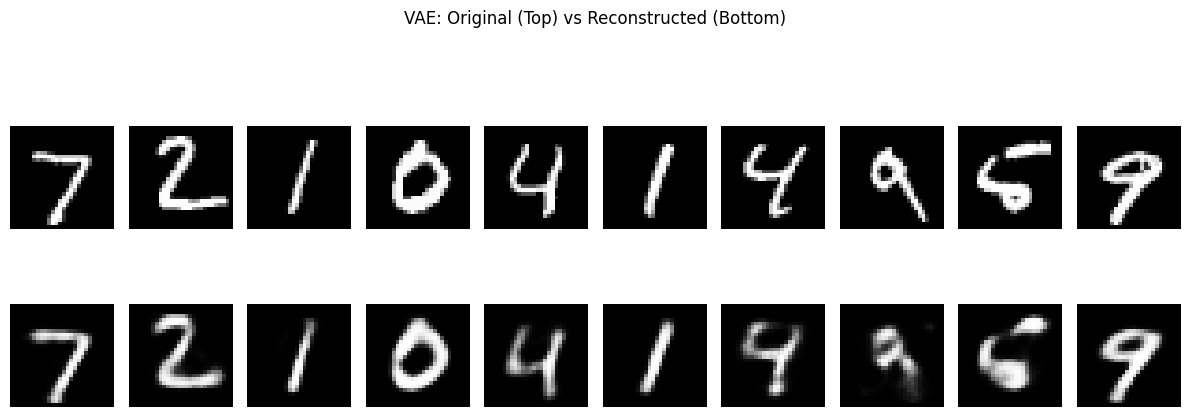

In [10]:
# Display Original and Reconstructed Images

vae_model.eval()

images, _ = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    reconstructed, _, _ = vae_model(images)

images = images.cpu()
reconstructed = reconstructed.cpu()

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.axis("off")

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("VAE: Original (Top) vs Reconstructed (Bottom)")
plt.tight_layout()
plt.show()

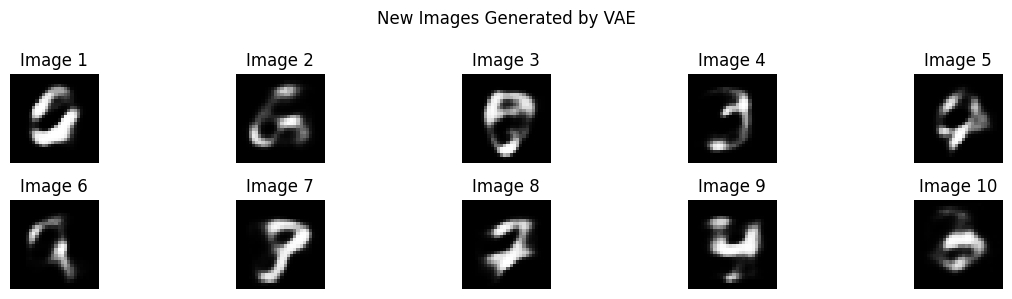

In [11]:
# Generate New Handwritten Digits

vae_model.eval()

with torch.no_grad():
    z = torch.randn(10, 20).to(device)
    generated_images = vae_model.decode(z)

generated_images = generated_images.cpu().view(-1, 28, 28)

plt.figure(figsize=(12, 3))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(generated_images[i], cmap="gray")
    plt.axis("off")
    plt.title(f"Image {i + 1}")

plt.suptitle("New Images Generated by VAE")
plt.tight_layout()
plt.show()

## COMPARE AUTOENCODER AND VAE LOSS

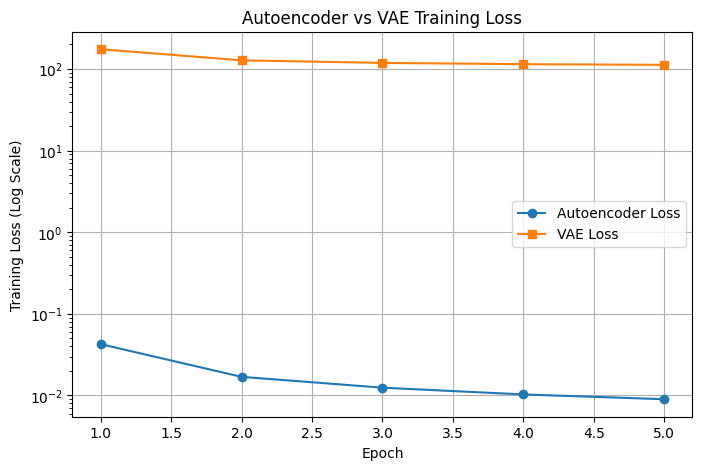

In [14]:
# Step 14: Compare Autoencoder and VAE Loss

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, ae_epochs + 1),
    ae_losses,
    marker="o",
    label="Autoencoder Loss"
)

plt.plot(
    range(1, vae_epochs + 1),
    vae_losses,
    marker="s",
    label="VAE Loss"
)

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training Loss (Log Scale)")
plt.title("Autoencoder vs VAE Training Loss")
plt.legend()
plt.grid(True)
plt.show()

## Result

The Fully Connected Autoencoder and Variational Autoencoder were implemented
using PyTorch and trained on the MNIST dataset.

The Autoencoder reconstructed input images, while the VAE reconstructed
images and generated new samples using its latent space.
